# Recording: from spatial Views to result schemas

This tutorial covers one thing only: how to select states or mechanisms from the spatial extent of a Cell population and record them as results with static metadata. A minimal NetStim network only produces real events and synaptic responses; for the full treatment of Synapse placement, Connection pairing and Network assembly, see [synapse.ipynb](../synapse/synapse.ipynb), [connection.ipynb](../network/connection.ipynb) and [network.ipynb](../network/network.ipynb).

In [1]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import braincell
from braincell import mech
from braincell.filter import BranchSlice, at

brainstate.environ.set(precision=64)

## 1. Fix the two levels of selection first

The object `record()` is called on determines the spatial scope, and `observe.*` then determines what to record within that space:

```text
population members -> branch / region -> CV -> mechanism selector -> field
```

| Mechanism category | `type` | `name` | Extra identity | Minimal result row |
| --- | --- | --- | --- | --- |
| Channel | dynamics model, for example `Na_HH1952` | logical owner declared by the user, for example `nav` | - | `(cell, CV, channel owner)` |
| Ion | implementation model, for example `SodiumFixed` | logical owner, for example `na_pool` | `species="na"` | `(cell, CV, ion owner)` |
| Synapse | dynamics model, for example `ExpSyn` | logical group, for example `fast_ampa` | stable logical `ids` | one independent Synapse instance |

`type` answers "which set of equations is used", and `name` answers "which group the user declared". One type can have several names; the stable ID of a Synapse can further locate a single instance.

## 2. Build a Cell population with several logical owners

Four cells share one three-branch morphology with seven CVs. Two `IL` owners use the same type with different names and cover the soma and the dendrites respectively, which makes the difference between type and name directly visible.

In [2]:
soma = braincell.Branch.from_lengths(
    lengths=[20.0] * u.um, radii=[10.0, 10.0] * u.um, type="soma",
)
dend_a = braincell.Branch.from_lengths(
    lengths=[120.0] * u.um, radii=[2.0, 1.0] * u.um, type="dendrite",
)
dend_b = braincell.Branch.from_lengths(
    lengths=[160.0] * u.um, radii=[2.5, 0.8] * u.um, type="dendrite",
)
morphology = braincell.Morphology.from_root(soma, name="soma")
morphology.soma.dend_a = dend_a
morphology.soma.dend_b = dend_b

cell = braincell.Cell(
    morphology, cv_policy=braincell.CVPerBranchList((1, 3, 3)),
    pop_size=(4,), solver="staggered", V_init=-65.0 * u.mV, name="post",
)
whole = BranchSlice([0, 1, 2], 0.0, 1.0)
soma_region = BranchSlice([0], 0.0, 1.0)
dendrite_region = BranchSlice([1, 2], 0.0, 1.0)

cell.paint(whole, mech.Ion("SodiumFixed", name="na_pool", E=50.0 * u.mV))
cell.paint(whole, mech.Ion("PotassiumFixed", name="k_pool", E=-77.0 * u.mV))
cell.paint(whole, mech.Channel("Na_HH1952", name="nav", g_max=120.0 * u.mS / u.cm**2))
cell.paint(whole, mech.Channel("K_HH1952", name="kv", g_max=36.0 * u.mS / u.cm**2))
cell.paint(soma_region, mech.Channel("IL", name="leak_soma", g_max=0.3 * u.mS / u.cm**2, E=-54.387 * u.mV))
cell.paint(dendrite_region, mech.Channel("IL", name="leak_dend", g_max=0.3 * u.mS / u.cm**2, E=-54.387 * u.mV))

assert cell.n_cv == 7

### Channel and Ion Views

Spatial Views can be narrowed level by level; mechanism Views copy no runtime data and store only the selected logical rows. Channels support `by_type()` and `by_name()`/`[name]`; Ions also support `by_species()`. `get()`/`set()` require that exactly one `(type, name)` owner remains, so that parameter columns with different meanings are never mixed.

In [3]:
cell.channels['leak_soma'].get('E')

Quantity([-54.387 -54.387 -54.387 -54.387], "mV")

In [4]:
spatial_view = cell[[0, 2]].dendrite.cv[1:]
il_by_type = cell.channels.by_type("IL")
soma_leak_by_name = cell.channels["leak_soma"]
sodium_by_species = cell.ions.by_species("na")
sodium_by_type = cell.ions.by_type("SodiumFixed")
sodium_by_name = cell.ions["na_pool"]

display(pd.DataFrame([
    ("cell[[0, 2]].dendrite.cv[1:]", len(spatial_view), "population + branch type + CV"),
    ("cell.channels", len(cell.channels), "all Channel logical rows"),
    ("channels.by_type('IL')", len(il_by_type), f"names={il_by_type.names}"),
    ("channels['leak_soma']", len(soma_leak_by_name), f"types={soma_leak_by_name.types}"),
    ("ions.by_species('na')", len(sodium_by_species), f"names={sodium_by_species.names}"),
    ("ions.by_type('SodiumFixed')", len(sodium_by_type), f"names={sodium_by_type.names}"),
    ("ions['na_pool']", len(sodium_by_name), f"species={tuple(dict.fromkeys(sodium_by_name.species))}"),
], columns=["selection", "rows", "meaning"]))

assert set(il_by_type.names) == {"leak_soma", "leak_dend"}
assert sodium_by_species.names == sodium_by_type.names == sodium_by_name.names == ("na_pool",)

,selection,rows,meaning
0,"cell[[0, 2]].dendrite.cv[1:]",2,population + branch type + CV
1,cell.channels,84,all Channel logical rows
2,channels.by_type('IL'),28,"names=('leak_soma', 'leak_dend')"
3,channels['leak_soma'],4,"types=('IL',)"
4,ions.by_species('na'),28,"names=('na_pool',)"
5,ions.by_type('SodiumFixed'),28,"names=('na_pool',)"
6,ions['na_pool'],28,"species=('na',)"


## 3. Type, name and stable IDs in Synapse Views

Each cell places `fast_ampa` and `slow_ampa` on the same dendrite CV, both using `ExpSyn`, plus one `Exp2Syn` on the other dendrite. A type selector can therefore aggregate across two names, while names and IDs can narrow further to one logical group or a few independent instances.

In [5]:
fast_ampa = mech.Synapse("ExpSyn", name="fast_ampa", tau=1.5 * u.ms, e=0.0 * u.mV)
slow_ampa = mech.Synapse("ExpSyn", name="slow_ampa", tau=4.0 * u.ms, e=0.0 * u.mV)
gaba = mech.Synapse("Exp2Syn", name="gaba", tau1=0.5 * u.ms, tau2=6.0 * u.ms, e=-75.0 * u.mV)

cell.place(at("dend_a", 0.35), fast_ampa)
cell.place(at("dend_a", 0.35), slow_ampa)
cell.place(at("dend_b", 0.70), gaba)

exp_synapses = cell.synapses.by_type("ExpSyn")
fast_synapses = cell.synapses["fast_ampa"]
selected_synapses = fast_synapses[[0, 2]]
display(pd.DataFrame([
    ("cell.synapses", len(cell.synapses), tuple(dict.fromkeys(cell.synapses.synapse_type)), tuple(dict.fromkeys(cell.synapses.name))),
    ("synapses.by_type('ExpSyn')", len(exp_synapses), tuple(dict.fromkeys(exp_synapses.synapse_type)), tuple(dict.fromkeys(exp_synapses.name))),
    ("synapses['fast_ampa']", len(fast_synapses), tuple(dict.fromkeys(fast_synapses.synapse_type)), tuple(dict.fromkeys(fast_synapses.name))),
    ("fast_synapses[[0, 2]]", len(selected_synapses), tuple(dict.fromkeys(selected_synapses.synapse_type)), tuple(dict.fromkeys(selected_synapses.name))),
], columns=["selection", "rows", "types", "names"]))
print("selected stable IDs:", selected_synapses.id)

assert len(cell.synapses) == 12
assert len(exp_synapses) == 8
assert len(fast_synapses) == 4
assert len(selected_synapses) == 2

,selection,rows,types,names
0,cell.synapses,12,"(ExpSyn, Exp2Syn)","(fast_ampa, slow_ampa, gaba)"
1,synapses.by_type('ExpSyn'),8,"(ExpSyn,)","(fast_ampa, slow_ampa)"
2,synapses['fast_ampa'],4,"(ExpSyn,)","(fast_ampa,)"
3,"fast_synapses[[0, 2]]",2,"(ExpSyn,)","(fast_ampa,)"


selected stable IDs: [0 2]


## 4. Observables and output rows

| Request | Selector | Rows for `reduce="none"` or a state | Default `reduce="sum"` |
| --- | --- | --- | --- |
| Cell state | `observe.state("V")` | one row per selected `(cell, CV)` | not applicable |
| Channel | `channel(type=...)` or `channel(name=...)` | one row per `(cell, CV, owner)` | sums the matched channels of the same `(cell, CV)` |
| Ion | `ion(species/type/name=...)` | one row per `(cell, CV, owner)` | sums the matched ions of the same `(cell, CV)` |
| Synapse | `synapse(type/name/ids=...)` | one row per stable Synapse ID | sums the matched Synapses of the same `(cell, CV)` |
| Membrane current | `observe.membrane_current()` | total membrane current density of each selected `(cell, CV)` | already a total |

The membrane potential is written `"V"`, the same name as `cell.V`, and the field of the result rows is also `"V"`; `cell.record(name, "V")` is shorthand for `observe.state("V")`. Other state names (including `"v"`, removed in 0.3) raise `KeyError` at declaration. States are not reduced. `current()` sums by default; use `current(reduce="none")` explicitly to tell the contributors apart. Selector arguments are mutually exclusive: for example, `type=` and `name=` cannot be passed together.

In [6]:
cell[[0, 2]].dendrite.cv[1:].record(
    "dend_v", braincell.observe.state("V"), period=0.1 * u.ms,
)
cell.soma.record(
    "nav_p", braincell.observe.channel(name="nav").state("p"), frequency=10.0 * u.kHz,
)
cell.soma.record(
    "sodium_current", braincell.observe.ion(species="na").current(), period=0.1 * u.ms,
)
cell.soma.record(
    "channel_current_rows", braincell.observe.channel().current(reduce="none"), period=0.1 * u.ms,
)
cell.soma.record(
    "channel_current_sum", braincell.observe.channel().current(), period=0.1 * u.ms,
)
cell.record("exp_g", braincell.observe.synapse(type="ExpSyn").state("g"), period=0.1 * u.ms)
cell.record("fast_g", braincell.observe.synapse(name="fast_ampa").state("g"), period=0.1 * u.ms)
cell.record("selected_g", braincell.observe.synapse(ids=selected_synapses.id).state("g"), period=0.1 * u.ms)
cell.record(
    "exp_current_rows", braincell.observe.synapse(type="ExpSyn").current(reduce="none"), period=0.1 * u.ms,
)
cell.record(
    "exp_current_sum", braincell.observe.synapse(type="ExpSyn").current(), period=0.1 * u.ms,
)
cell.soma.record(
    "membrane_current", braincell.observe.membrane_current(), period=0.1 * u.ms, start=0.5 * u.ms,
)

pd.DataFrame({
    "recording": tuple(cell.recordings),
    "period/frequency/start": [
        "period=0.1 ms", "frequency=10 kHz", "period=0.1 ms",
        "period=0.1 ms", "period=0.1 ms", "period=0.1 ms",
        "period=0.1 ms", "period=0.1 ms", "period=0.1 ms",
        "period=0.1 ms", "period=0.1 ms, start=0.5 ms",
    ],
})

,recording,period/frequency/start
0,dend_v,period=0.1 ms
1,nav_p,frequency=10 kHz
2,sodium_current,period=0.1 ms
3,channel_current_rows,period=0.1 ms
4,channel_current_sum,period=0.1 ms
5,exp_g,period=0.1 ms
6,fast_g,period=0.1 ms
7,selected_g,period=0.1 ms
8,exp_current_rows,period=0.1 ms
9,exp_current_sum,period=0.1 ms


Declaring a recording creates no point mechanism and does not change the Cell layout. `period` and `frequency` are mutually exclusive; when both are omitted, every `dt` is sampled. The actual `period` and `start` are validated at the first run, once `dt` is known, and must align with whole `dt` steps. All recordings must be declared before initialization.

## 5. Driving with a minimal Network

One NetStim source broadcasts to three Synapse groups. The Connections here only produce observable signals; they introduce no pairing and no network-level Synapse shortcut creation.

In [7]:
stim = braincell.NetStim(size=1, start=1.0 * u.ms, number=4, interval=2.0 * u.ms, noise=0.0)
network = braincell.Network("recording_demo", seed=7)
stim_pop = network.add_population("stim", stim)
post_pop = network.add_population("post", cell)

network.connect("drive_fast", source=stim_pop, synapse=post_pop.synapses["fast_ampa"], weight=0.05 * u.uS)
network.connect("drive_slow", source=stim_pop, synapse=post_pop.synapses["slow_ampa"], weight=0.03 * u.uS)
network.connect("drive_gaba", source=stim_pop, synapse=post_pop.synapses["gaba"], weight=0.02 * u.uS)

assert repr(network) == "Network(name='recording_demo', populations=2, connections=3, rows=12)"
print(network)

Network(name='recording_demo', populations=2, connections=3, rows=12)
  populations:
    stim: size=1, kind=netstim, model=NetStim, initialized=False
    post: size=4, kind=cell, model=Cell, initialized=False
  connections:
    post: connections=3, rows=12
      drive_fast: NetStim(stim) -> ExpSyn(fast_ampa), rows=4
      drive_slow: NetStim(stim) -> ExpSyn(slow_ampa), rows=4
      drive_gaba: NetStim(stim) -> Exp2Syn(gaba), rows=4


In [8]:
DT = 0.025 * u.ms
first = network.run(dt=DT, duration=5.0 * u.ms)
second = network.run(dt=DT, duration=5.0 * u.ms)
result = braincell.NetworkResult.concat((first, second))

samples = result.samples["post"]
events = result.events["stim"]["spike"]
assert samples["channel_current_rows"].schema.size == 12
assert samples["channel_current_sum"].schema.size == 4
assert samples["exp_g"].schema.size == 8
assert samples["selected_g"].schema.size == 2
assert samples["exp_current_rows"].schema.size == 8
assert samples["exp_current_sum"].schema.size == 4
assert len(events.time) == 4
assert np.isclose(samples["membrane_current"].time[0].to_decimal(u.ms), 0.5)

pd.DataFrame({
    "recording": list(samples),
    "samples": [block.values.shape[0] for block in samples.values()],
    "rows": [block.schema.size for block in samples.values()],
    "unit": [str(block.schema.rows[0].unit) for block in samples.values()],
})

,recording,samples,rows,unit
0,dend_v,100,10,mV
1,nav_p,100,4,None
2,sodium_current,100,4,mS * mV / cm^2
3,channel_current_rows,100,12,mS * mV / cm^2
4,channel_current_sum,100,4,mS * mV / cm^2
5,exp_g,100,8,uS
6,fast_g,100,4,uS
7,selected_g,100,2,uS
8,exp_current_rows,100,8,nA
9,exp_current_sum,100,4,nA


## 6. SampleBlock, Schema and sparse Events

`result.samples[population][recording]` returns an immutable `SampleBlock`: the first axis of `values` is the sample time, and the last axis corresponds exactly to `schema.rows`. Each `RecordingRow` stores the spatial identity and the mechanism identity, so results never depend on guessing from column names. A summed current row points through `contributor_ids` to the positions of the original contributors in this recording that took part in the reduction.

Source events are not a regularly sampled matrix but a sparse `EventSeries(time, source_id, count)` in `result.events[population][port]`.

In [9]:
def schema_frame(block):
    return pd.DataFrame([{
        "population": row.population_index,
        "CV": row.cv_id,
        "branch": row.branch_id,
        "category": row.mechanism_category,
        "type": row.mechanism_type,
        "name": row.mechanism_name,
        "synapse_id": row.synapse_id,
        "field": row.field,
        "contributors": row.contributor_ids,
        "unit": str(row.unit),
    } for row in block.schema.rows])

display("Channel contributors", schema_frame(samples["channel_current_rows"]))
display("Channel current reduced by (cell, CV)", schema_frame(samples["channel_current_sum"]))
display("ExpSyn logical instances", schema_frame(samples["exp_g"]))
display(pd.DataFrame({
    "time (ms)": events.time.to_decimal(u.ms),
    "source_id": events.source_id,
    "count": events.count,
}))

'Channel contributors'

,population,CV,branch,category,type,name,synapse_id,field,contributors,unit
0,0,0,0,channel,Na_HH1952,nav,None,current,(),mS * mV / cm^2
1,0,0,0,channel,K_HH1952,kv,None,current,(),mS * mV / cm^2
2,0,0,0,channel,IL,leak_soma,None,current,(),mS * mV / cm^2
3,1,0,0,channel,Na_HH1952,nav,None,current,(),mS * mV / cm^2
4,1,0,0,channel,K_HH1952,kv,None,current,(),mS * mV / cm^2
5,1,0,0,channel,IL,leak_soma,None,current,(),mS * mV / cm^2
6,2,0,0,channel,Na_HH1952,nav,None,current,(),mS * mV / cm^2
7,2,0,0,channel,K_HH1952,kv,None,current,(),mS * mV / cm^2
8,2,0,0,channel,IL,leak_soma,None,current,(),mS * mV / cm^2
9,3,0,0,channel,Na_HH1952,nav,None,current,(),mS * mV / cm^2


'Channel current reduced by (cell, CV)'

,population,CV,branch,category,type,name,synapse_id,field,contributors,unit
0,0,0,0,None,None,None,None,channel_current,"(0, 1, 2)",mS * mV / cm^2
1,1,0,0,None,None,None,None,channel_current,"(3, 4, 5)",mS * mV / cm^2
2,2,0,0,None,None,None,None,channel_current,"(6, 7, 8)",mS * mV / cm^2
3,3,0,0,None,None,None,None,channel_current,"(9, 10, 11)",mS * mV / cm^2


'ExpSyn logical instances'

,population,CV,branch,category,type,name,synapse_id,field,contributors,unit
0,0,2,1,synapse,ExpSyn,fast_ampa,0,g,(),uS
1,0,2,1,synapse,ExpSyn,slow_ampa,4,g,(),uS
2,1,2,1,synapse,ExpSyn,fast_ampa,1,g,(),uS
3,1,2,1,synapse,ExpSyn,slow_ampa,5,g,(),uS
4,2,2,1,synapse,ExpSyn,fast_ampa,2,g,(),uS
5,2,2,1,synapse,ExpSyn,slow_ampa,6,g,(),uS
6,3,2,1,synapse,ExpSyn,fast_ampa,3,g,(),uS
7,3,2,1,synapse,ExpSyn,slow_ampa,7,g,(),uS


,time (ms),source_id,count
0,1.0,0,1
1,3.0,0,1
2,5.0,0,1
3,7.0,0,1


## 7. Continued runs and immutable results

Two consecutive `run()` calls share the global recording schedule, the Cell states, the event history and the delay queues. `NetworkResult.concat()` accepts only segments that are contiguous in time, have the same `dt` and have exactly the same schema. `reset_state()` restores the initialization baseline but does not return an editable topology.

In [10]:
network.reset_state()
continuous = network.run(dt=DT, duration=10.0 * u.ms)

for name, split_block in result.samples["post"].items():
    full_block = continuous.samples["post"][name]
    unit = split_block.schema.rows[0].unit
    split_values = split_block.values if unit is None else split_block.values.to_decimal(unit)
    full_values = full_block.values if unit is None else full_block.values.to_decimal(unit)
    np.testing.assert_allclose(split_values, full_values, rtol=1e-6, atol=1e-7)

np.testing.assert_allclose(
    result.events["stim"]["spike"].time.to_decimal(u.ms),
    continuous.events["stim"]["spike"].time.to_decimal(u.ms),
)
print("split 5 + 5 ms matches reset + continuous 10 ms")

split 5 + 5 ms matches reset + continuous 10 ms


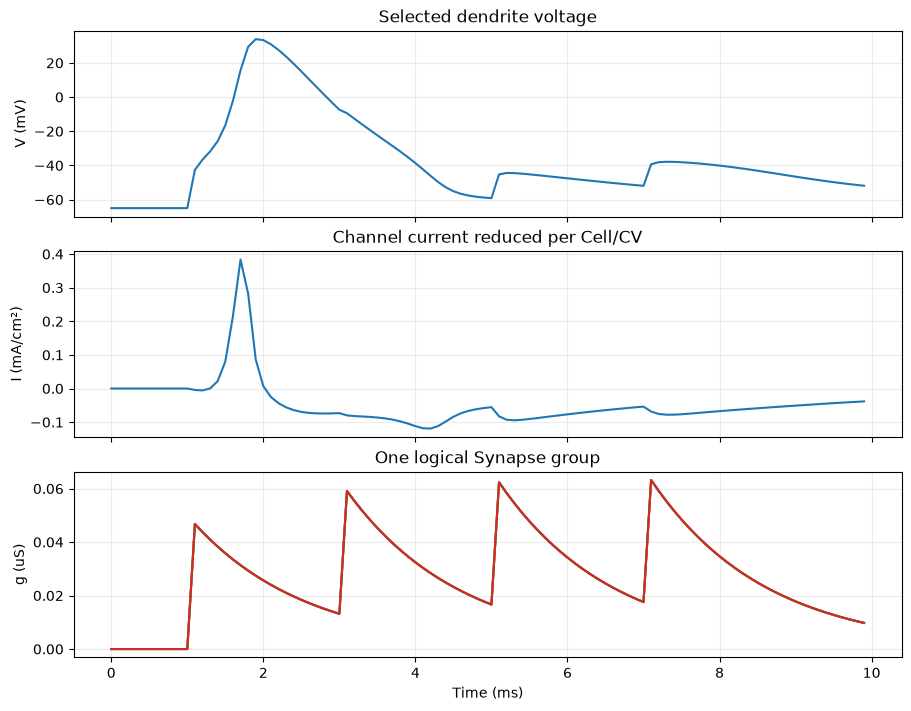

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True, constrained_layout=True)

voltage = samples["dend_v"]
axes[0].plot(voltage.time.to_decimal(u.ms), voltage.values[:, 0].to_decimal(u.mV))
axes[0].set(ylabel="V (mV)", title="Selected dendrite voltage")

channel_current = samples["channel_current_sum"]
axes[1].plot(
    channel_current.time.to_decimal(u.ms),
    channel_current.values[:, 0].to_decimal(u.mA / u.cm**2),
)
axes[1].set(ylabel="I (mA/cm²)", title="Channel current reduced per Cell/CV")

fast_g = samples["fast_g"]
axes[2].plot(fast_g.time.to_decimal(u.ms), fast_g.values.to_decimal(u.uS))
axes[2].set(xlabel="Time (ms)", ylabel="g (uS)", title="One logical Synapse group")
for axis in axes:
    axis.grid(alpha=0.25)
plt.show()

## 8. Running a Cell on its own: `record(name, "V")` and `RunResult.spikes`

Outside a Network, `Cell.run()` returns a `RunResult`. `RunResult.spikes` is the sparse `EventSeries` of the Cell's `"spike"` port, in the same format as `result.events[population]["spike"]` once the same Cell is placed in a Network:

- The port reads `cell.spike` of the CV that contains the midpoint of the root branch; `metadata["cv_id"]` gives the CV of each row.
- If a step from `t_k` to `t_k + dt` takes the voltage from below `V_th` to `V_th` or above, one event is recorded at `t_k + dt`, the end of the step, with `count` 1, as NEURON's `NetCon.record` does; a voltage that stays above threshold produces no further events.
- A run reports the events of its own steps, at times in `(start_time, stop_time]`: a crossing in its last step is at its `stop_time`, so split runs concatenate to one run.
- `source_id` is the population member; with a batch axis, rows are flattened in C order over `(batch,) + pop_size`, and `metadata["batch_index"]` and `metadata["population_index"]` give the batch and member of each row.
- When run under `jax.jit` or `jax.grad`, the number of events depends on the data, and `spikes` is `None`.

Both `RunResult` and `NetworkResult` are JAX pytrees; `jax.block_until_ready(result)` waits for the arrays they contain.

In [12]:
def hh_population(amplitudes):
    """Point HH cells, one per clamp amplitude: pop_size is the shape of ``amplitudes``."""
    hh = braincell.Cell.point(
        amplitudes.shape, length=20.0 * u.um, radius=10.0 * u.um, V_init=-65.0 * u.mV, solver="rk4"
    )
    hh.paint(
        mech.Ion("SodiumFixed", E=50.0 * u.mV),
        mech.Ion("PotassiumFixed", E=-77.0 * u.mV),
        mech.Channel("Na_HH1952", name="na", g_max=120.0 * u.mS / u.cm**2),
        mech.Channel("K_HH1952", name="k", g_max=36.0 * u.mS / u.cm**2),
        mech.Channel("IL", name="leak", g_max=0.3 * u.mS / u.cm**2, E=-54.3 * u.mV),
    )
    hh.place(at("soma", 0.5), mech.CurrentClamp(delay=1.0 * u.ms, durations=18.0 * u.ms, amplitudes=amplitudes))
    return hh


amplitudes = [0.0, 0.1, 0.2] * u.nA
hh = hh_population(amplitudes)
hh.record("V", "V")
standalone = hh.run(dt=DT, duration=20.0 * u.ms)
spikes = standalone.spikes

# The same Cell in a Network reports the same events.
spiking_network = braincell.Network("spikes_demo")
spiking_network.add_population("hh", hh_population(amplitudes))
in_network = spiking_network.run(dt=DT, duration=20.0 * u.ms).events["hh"]["spike"]
np.testing.assert_array_equal(spikes.source_id, in_network.source_id)
np.testing.assert_allclose(spikes.time.to_decimal(u.ms), in_network.time.to_decimal(u.ms))
assert spikes.metadata["port"] == "spike"

pd.DataFrame({
    "time (ms)": spikes.time.to_decimal(u.ms),
    "source_id": spikes.source_id,
    "count": spikes.count,
    "cv_id": spikes.metadata["cv_id"][spikes.source_id],
})

,time (ms),source_id,count,cv_id
0,2.45,2,1,0
1,3.20,1,1,0
2,15.35,2,1,0
3,19.45,1,1,0


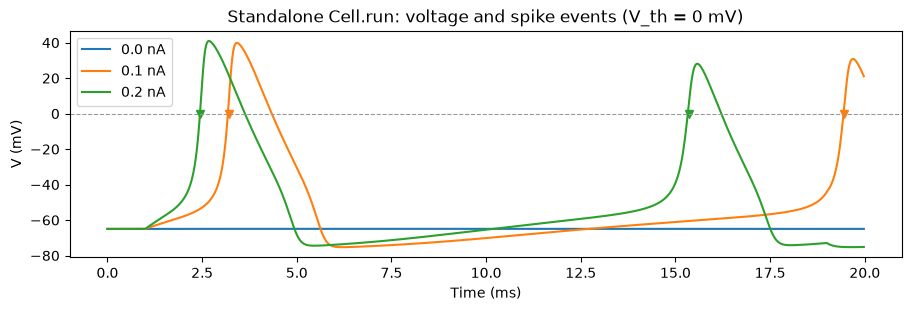

In [13]:
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
v = standalone.samples["V"]
for member, amplitude in enumerate(amplitudes.to_decimal(u.nA)):
    line, = ax.plot(v.time.to_decimal(u.ms), v.values[:, member].to_decimal(u.mV), label=f"{amplitude} nA")
    member_times = spikes.time[spikes.source_id == member].to_decimal(u.ms)
    ax.plot(member_times, np.zeros_like(member_times), "v", color=line.get_color())
ax.axhline(0.0, color="0.6", lw=0.8, ls="--")
ax.set(xlabel="Time (ms)", ylabel="V (mV)", title="Standalone Cell.run: voltage and spike events (V_th = 0 mV)")
ax.legend()
plt.show()

## 9. A population with several axes

`pop_size` can have several axes: `(2, 3)` is two rows of three cells. `cell[...]` then selects members the way NumPy basic indexing selects elements of a `(2, 3)` array, with one integer or slice per axis (`cell[1, 2]`, `cell[:, 1]`, `cell[0]`), and the view's `shape` (its `pop_size`) is the shape that indexing gives. Once a selection has one axis left, the one-dimensional rules apply again, so `cell[1][[2, 0]]` lists members in that order.

A recording flattens the members in C order. `RecordingRow.population_index` is the flat index of the member, the same index a spike's `source_id` uses, so `values.reshape(n_samples, *pop_size)` restores the grid of a whole-Cell recording of point cells (a cable Cell adds its CVs as a last axis). The values are those of the same Cell with `pop_size=(6,)`.

In [14]:
grid_amplitudes = [[0.0, 0.05, 0.1], [0.1, 0.0, 0.05]] * u.nA
grid = hh_population(grid_amplitudes)
views = {"grid": grid, "grid[:, 1]": grid[:, 1], "grid[1, 2]": grid[1, 2], "grid[1][[2, 0]]": grid[1][[2, 0]]}
shapes = {label: view.pop_size for label, view in views.items()}  # views go stale at the first run
for label, view in views.items():
    view.record(label, "V")
grid_result = grid.run(dt=DT, duration=20.0 * u.ms)

# The same Cell with one axis records the same rows and values.
flat = hh_population(grid_amplitudes.reshape(6))
flat.record("V", "V")
flat_result = flat.run(dt=DT, duration=20.0 * u.ms)
whole = grid_result.samples["grid"]
np.testing.assert_allclose(
    whole.values.to_decimal(u.mV), flat_result.samples["V"].values.to_decimal(u.mV), rtol=1e-12, atol=1e-10
)
np.testing.assert_array_equal(grid_result.spikes.source_id, flat_result.spikes.source_id)

display(pd.DataFrame([
    {
        "view": label,
        "pop_size": shapes[label],
        "population_index of the rows": [row.population_index for row in grid_result.samples[label].schema.rows],
        "values": grid_result.samples[label].values.shape,
    }
    for label in views
]))
print("spikes per member:\n", np.bincount(grid_result.spikes.source_id, minlength=6).reshape(grid.pop_size))

,view,pop_size,population_index of the rows,values
0,grid,"(2, 3)","[0, 1, 2, 3, 4, 5]","(800, 6)"
1,"grid[:, 1]","(2,)","[1, 4]","(800, 2)"
2,"grid[1, 2]","(1,)",[5],"(800, 1)"
3,"grid[1][[2, 0]]","(2,)","[5, 3]","(800, 2)"


spikes per member:
 [[0 1 2]
 [2 0 1]]


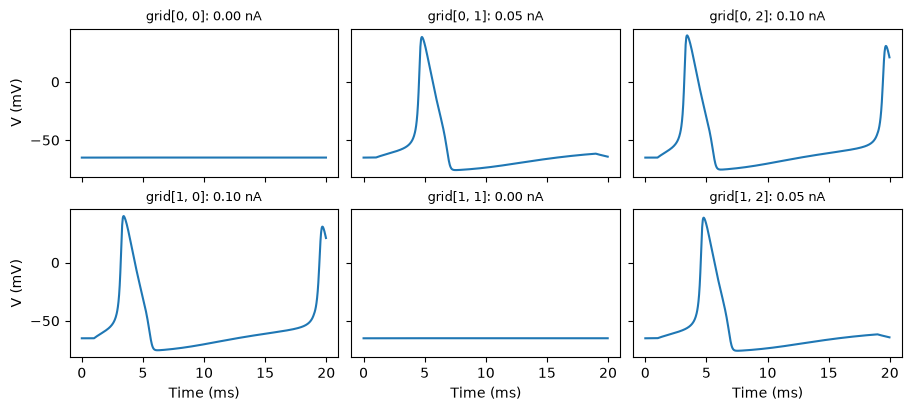

In [15]:
voltage = whole.values.to_decimal(u.mV).reshape((len(whole.time),) + grid.pop_size)
fig, axes = plt.subplots(*grid.pop_size, figsize=(9, 4), sharex=True, sharey=True, constrained_layout=True)
for (row, column), ax in np.ndenumerate(axes):
    ax.plot(whole.time.to_decimal(u.ms), voltage[:, row, column])
    ax.set_title(f"grid[{row}, {column}]: {grid_amplitudes[row, column].to_decimal(u.nA):.2f} nA", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("V (mV)")
plt.show()

A list, an array or a boolean in a selection with more than one axis raises `TypeError`, and an index outside its axis raises `IndexError`, both where the selection is made. Views of a multi-dimensional Cell select and record; reading or writing state and parameters through them (`V`, `spike`, `channels`, `set`, ...) and recording `observe.output(...)` need a one-dimensional `pop_size` and raise `ValueError`.

In [16]:
attempts = {
    "grid[[0, 1]]": lambda: grid[[0, 1]],
    "grid[2, 0]": lambda: grid[2, 0],
    "grid[0, 1].V": lambda: grid[0, 1].V,
}
for label, attempt in attempts.items():
    try:
        attempt()
    except (IndexError, TypeError, ValueError) as error:
        print(f"{label}: {type(error).__name__}: {error}\n")

grid[[0, 1]]: TypeError: Cell population selection of members of shape (2, 3) takes one integer or slice per axis, as in cell[1, 2] or cell[:, 1]; got [0, 1]. Integer sequences select members only on a one-dimensional selection, such as cell[0][[0, 2]].

grid[2, 0]: IndexError: Cell population index 2 is outside axis 0 of size 2.

grid[0, 1].V: ValueError: CellView.V requires a one-dimensional pop_size; got (2, 3). On a multi-dimensional population, views select members (cell[i, j], cell[:, j]) to record them.



## Summary

The spatial View decides where to record, the observable selector decides which mechanism owner or Synapse instance to record, and the field decides what to read. Regular samples go into a `SampleBlock` with a schema, and source events go into a sparse `EventSeries`; NetworkResult organizes both by population name. A Cell run on its own puts its regular samples into `RunResult.samples` and its own spikes into `RunResult.spikes`, in the same format. On a `pop_size` with several axes, views select members by NumPy basic indexing and recordings list them in C order.